# Smartphone ML Intelligence

## 05 — Smartphone Market Segmentation

### Objective

Segment currently available smartphones into four interpretable market groups using numerical characteristics related to price, performance, display, battery, charging, camera, and form factor.


The main objective is then to determine:

- how the four smartphone groups differ,
- which numerical features contribute most strongly to separating them,
- how brands and categorical technologies are distributed across the resulting segments,
- and whether the four-cluster representation produces meaningful market categories.

### 1. Importing and Loading 

In [201]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
N_CLUSTERS = 4

In [202]:
DATA_PATH = Path("../data/processed/phones_clean.csv")

data = pd.read_csv(
    DATA_PATH,
    parse_dates=["launch_date"]
)

con = duckdb.connect()
con.register("phones", data)

query = """
SELECT *
FROM phones
WHERE availability=1
"""

phones = con.execute(query).df()


print(f"Rows: {phones.shape[0]}")
print(f"Columns: {phones.shape[1]}")

phones.head()

Rows: 154
Columns: 48


,name,brand,sale,processor_type,processor,fab,ram_type,rom_type,display_type,size,...,speaker,wireless_charging,ip_rating,price,availability,has_ultrawide,has_third_camera,has_fourth_camera,launch_year,phone_age_days
0,Galaxy A07,Samsung,Offline,Mediatek,Dimensity 6300,6,LPDDR4X,UFS 2.2,IPS LCD,6.7,...,Mono,False,54,20000,1,False,True,False,2026,248
1,Galaxy A17,Samsung,Offline,Exynos,1330,5,LPDDR4X,UFS 2.2,Amoled,6.7,...,Mono,False,54,28000,1,True,True,False,2025,408
2,Galaxy A27,Samsung,Offline,Snapdragon,6 Gen 3,4,LPDDR5X,UFS 3.1,Amoled,6.7,...,Mono,False,64,34000,1,True,True,False,2026,108
3,Galaxy A36,Samsung,Offline,Snapdragon,6 Gen 3,4,LPDDR5,UFS 2.2,Amoled,6.7,...,Stereo,False,67,36500,1,True,True,False,2025,588
4,Galaxy A37,Samsung,Offline,Exynos,1480,4,LPDDR5X,UFS 3.1,Amoled,6.7,...,Stereo,False,68,47000,1,True,True,False,2026,200


### 2. Analysing Features

In [203]:
def encode_binary_features(df):
    df = df.copy()

    df["display_type"] = df["display_type"].map({
        "Amoled": 1,
        "IPS LCD": 0
    })

    df["curved_display"] = df["curved_display"].astype(int)

    df["wireless_charging"] = df["wireless_charging"].astype(int)

    return df

In [204]:
phones_encoded = encode_binary_features(phones)

In [205]:
continuous_features = [
    "price",
    "antutu",
    "refresh_rate",
    "battery",
    "charging_speed",
    "main",
    "useful_camera_number",
    "size",
    "ppi",
    "thickness",
    "ip_rating"
]

binary_features = [
    "display_type",
    "curved_display",
    "wireless_charging"
]

features = continuous_features + binary_features

X = phones_encoded[features].copy()

print("Number of smartphones:", X.shape[0])
print("Number of clustering features:", X.shape[1])

X.head()

Number of smartphones: 154
Number of clustering features: 14


,price,antutu,refresh_rate,battery,charging_speed,main,useful_camera_number,size,ppi,thickness,ip_rating,display_type,curved_display,wireless_charging
0,20000,450401,120,6000,25,50,1,6.7,262,8.2,54,0,0,0
1,28000,473905,90,5000,25,50,2,6.7,358,7.5,54,1,0,0
2,34000,892500,120,5000,25,50,2,6.7,385,7.8,64,1,0,0
3,36500,620000,120,5000,45,50,3,6.7,385,7.4,67,1,0,0
4,47000,713393,120,5000,45,50,2,6.7,385,7.4,68,1,0,0


### 3. Scaling 

In [206]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=features,
    index=X.index
)

X_scaled.head()

,price,antutu,refresh_rate,battery,charging_speed,main,useful_camera_number,size,ppi,thickness,ip_rating,display_type,curved_display,wireless_charging
0,-0.796767,-0.915918,-0.385338,-0.351563,-1.096014,-0.199462,-1.109664,-0.072297,-1.703140,0.110595,-2.490032,-1.632993,-0.408248,-0.502028
1,-0.579378,-0.892659,-2.275211,-1.098867,-1.096014,-0.199462,0.077060,-0.072297,-0.506181,-1.124865,-2.490032,0.612372,-0.408248,-0.502028
2,-0.416337,-0.478437,-0.385338,-1.098867,-1.096014,-0.199462,0.077060,-0.072297,-0.169537,-0.595382,-0.395740,0.612372,-0.408248,-0.502028
3,-0.348403,-0.748090,-0.385338,-1.098867,-0.401992,-0.199462,1.263784,-0.072297,-0.169537,-1.301359,0.232548,0.612372,-0.408248,-0.502028
4,-0.063081,-0.655673,-0.385338,-1.098867,-0.401992,-0.199462,0.077060,-0.072297,-0.169537,-1.301359,0.441977,0.612372,-0.408248,-0.502028


### 4. Running the four-cluster model

In [207]:
from sklearn.cluster import KMeans

N_CLUSTERS = 4
RANDOM_STATE = 42

kmeans = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_STATE,
    n_init=20
)

cluster_labels = kmeans.fit_predict(X_scaled)

In [208]:
segmented_phones = phones.copy()

segmented_phones["cluster"] = cluster_labels

In [209]:
cluster_distribution = (
    segmented_phones["cluster"]
    .value_counts()
    .sort_index()
    .to_frame("smartphones")
)

cluster_distribution["share_pct"] = (
    cluster_distribution["smartphones"]
    / len(segmented_phones)
    * 100
).round(2)

cluster_distribution

,smartphones,share_pct
cluster,,
0,32,20.78
1,42,27.27
2,28,18.18
3,52,33.77


### 5. Numerical cluster profiles

In [210]:
cluster_numeric_profile = (
    segmented_phones
    .groupby("cluster")[continuous_features]
    .mean()
    .round(2)
)

cluster_numeric_profile

,price,antutu,refresh_rate,battery,charging_speed,main,useful_camera_number,size,ppi,thickness,ip_rating
cluster,,,,,,,,,,,
0,59156.25,1257509.19,114.19,5360.34,45.88,49.69,2.47,6.58,423.47,7.98,64.19
1,20440.48,583539.76,125.43,6700.00,32.14,41.67,1.12,6.78,287.45,8.49,62.67
2,103535.71,3075783.54,129.11,5568.04,71.07,76.50,2.89,6.66,465.32,7.79,68.57
3,37403.85,1173676.19,132.40,7454.08,75.12,65.54,1.75,6.77,437.13,8.14,68.10


### 5. Binary Feature Profiles

In [211]:
binary_profile = phones_encoded[
    binary_features
].copy()

binary_profile["cluster"] = cluster_labels

cluster_binary_profile = (
    binary_profile
    .groupby("cluster")[binary_features]
    .mean()
    .mul(100)
    .round(1)
)

cluster_binary_profile

,display_type,curved_display,wireless_charging
cluster,,,
0,100.0,0.0,6.2
1,0.0,0.0,0.0
2,100.0,7.1,100.0
3,100.0,38.5,1.9


### 6. Combining Profiles Visually

In [212]:
scaled_profile = X_scaled.copy()
scaled_profile["cluster"] = cluster_labels

cluster_standardized_profile = (
    scaled_profile
    .groupby("cluster")
    .mean()
    .round(2)
)

cluster_standardized_profile

,price,antutu,refresh_rate,battery,charging_speed,main,useful_camera_number,size,ppi,thickness,ip_rating,display_type,curved_display,wireless_charging
cluster,,,,,,,,,,,,,,
0,0.27,-0.12,-0.75,-0.83,-0.37,-0.21,0.63,-0.78,0.31,-0.29,-0.36,0.61,-0.41,-0.35
1,-0.78,-0.78,-0.04,0.17,-0.85,-0.41,-0.97,0.40,-1.39,0.62,-0.67,-1.63,-0.41,-0.50
2,1.47,1.68,0.19,-0.67,0.50,0.48,1.14,-0.32,0.83,-0.62,0.56,0.61,-0.20,1.99
3,-0.32,-0.20,0.40,0.74,0.64,0.20,-0.22,0.33,0.48,0.01,0.46,0.61,0.69,-0.45


### 7. Heatmap of Cluster Characterstics

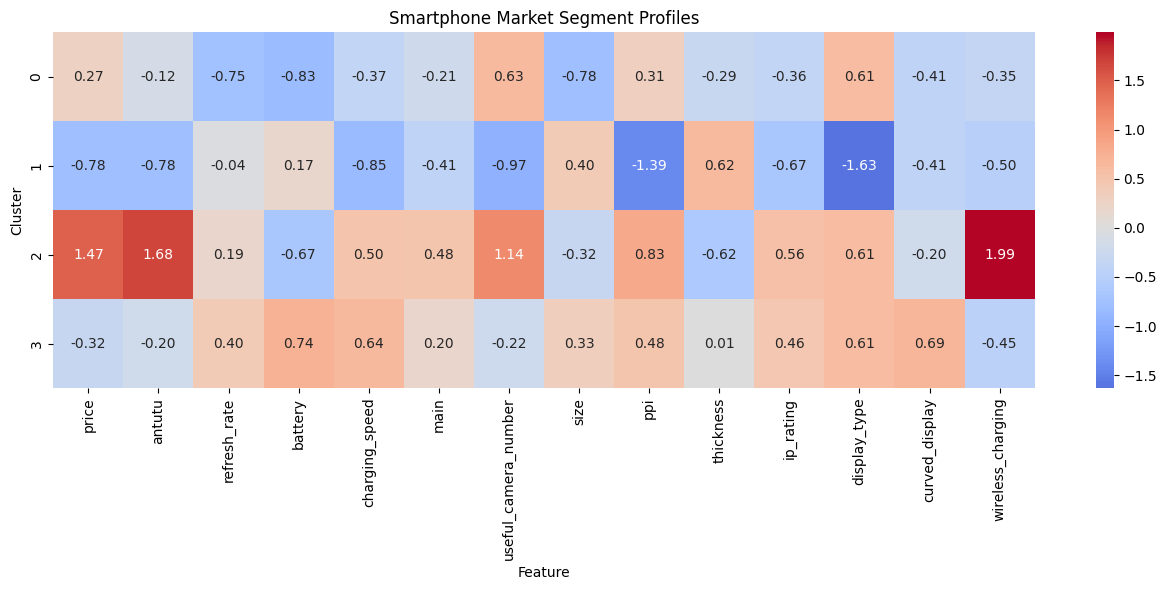

In [213]:
plt.figure(figsize=(13, 6))

sns.heatmap(
    cluster_standardized_profile,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Smartphone Market Segment Profiles")
plt.xlabel("Feature")
plt.ylabel("Cluster")

plt.tight_layout()
plt.show()

### 8. Finding Representative Smartphones

In [214]:
distances = kmeans.transform(X_scaled)

for cluster in range(N_CLUSTERS):

    cluster_mask = cluster_labels == cluster

    cluster_indices = X_scaled.index[
        cluster_mask
    ]

    cluster_distances = distances[
        cluster_mask,
        cluster
    ]

    representative_indices = (
        pd.Series(
            cluster_distances,
            index=cluster_indices
        )
        .sort_values()
        .head(10)
        .index
    )

    print(f"\nCluster {cluster}")

    display(
        segmented_phones.loc[
            representative_indices,
            [
                "brand",
                "name",
                "price",
                "size",
                "ppi",
                "antutu",
                "battery",
                "charging_speed",
                "main",
                "useful_camera_number",
                "refresh_rate",
                "thickness",
                "display_type",
                "curved_display",
                "wireless_charging"
            ]
        ]
    )


Cluster 0


,brand,name,price,size,ppi,antutu,battery,charging_speed,main,useful_camera_number,refresh_rate,thickness,display_type,curved_display,wireless_charging
10,Samsung,Galaxy F70 Pro,36000,6.70,385,892500,6000,45,50,2,120,7.8,Amoled,False,False
2,Samsung,Galaxy A27,34000,6.70,385,892500,5000,25,50,2,120,7.8,Amoled,False,False
5,Samsung,Galaxy A56,45000,6.70,385,908689,5000,45,50,3,120,7.4,Amoled,False,False
4,Samsung,Galaxy A37,47000,6.70,385,713393,5000,45,50,2,120,7.4,Amoled,False,False
3,Samsung,Galaxy A36,36500,6.70,385,620000,5000,45,50,3,120,7.4,Amoled,False,False
56,Nothing,Nothing Phone 4a,37000,6.78,440,1163152,5400,50,50,3,120,8.6,Amoled,False,False
148,Xiaomi,Xiaomi 17T,70000,6.59,460,2137999,6500,67,50,3,120,8.2,Amoled,False,False
58,Nothing,Nothing Phone 4b,32000,6.77,381,1025914,6000,33,50,2,120,8.6,Amoled,False,False
76,Oppo,Oppo Reno 16c,53000,6.57,397,985594,7000,80,50,3,120,8.4,Amoled,False,False
138,Vivo,Vivo V70,60000,6.59,459,1437195,6500,90,50,3,120,7.6,Amoled,False,False



Cluster 1


,brand,name,price,size,ppi,antutu,battery,charging_speed,main,useful_camera_number,refresh_rate,thickness,display_type,curved_display,wireless_charging
74,Oppo,Oppo K14x,16000,6.75,256,415000,6500,45,50,1,120,8.60,IPS LCD,False,False
132,Tecno,Tecno Spark 50,17000,6.78,256,521017,6500,45,50,1,120,8.20,IPS LCD,False,False
128,Tecno,Tecno Pop X,16000,6.78,256,521017,6500,45,13,1,120,8.20,IPS LCD,False,False
64,OnePlus,Oneplus N6x,21000,6.80,254,577520,7000,15,13,1,120,8.70,IPS LCD,False,False
41,Lava,Lava Bold N2,13000,6.75,260,515768,6000,18,13,1,120,8.75,IPS LCD,False,False
43,Lava,Lava Virat V1,13000,6.75,262,500000,6000,18,13,1,120,8.80,IPS LCD,False,False
115,Xiaomi,Redmi 15C,18500,6.90,254,467924,6000,33,50,1,120,8.00,IPS LCD,False,False
86,POCO,Poco C85,16500,6.90,254,467924,6000,33,50,1,120,8.00,IPS LCD,False,False
52,Motorola,Moto G37 Power,16000,6.60,264,596993,7000,30,50,1,120,8.90,IPS LCD,False,False
73,Oppo,Oppo K14 Lite,17000,6.75,256,308467,7000,15,13,1,120,9.00,IPS LCD,False,False



Cluster 2


,brand,name,price,size,ppi,antutu,battery,charging_speed,main,useful_camera_number,refresh_rate,thickness,display_type,curved_display,wireless_charging
143,Vivo,Vivo X300 Pro,120000,6.78,452,3646540,6510,90,50,3,120,8.0,Amoled,False,True
141,Vivo,Vivo X200T,60000,6.67,460,2825042,6200,90,50,3,120,8.0,Amoled,False,True
19,Samsung,Galaxy S25+,100000,6.70,513,2528942,4900,45,50,3,120,7.3,Amoled,False,True
23,Samsung,Galaxy S26+,135000,6.70,516,3115908,4900,45,50,3,120,7.3,Amoled,False,True
21,Samsung,Galaxy S26 FE,73000,6.70,385,2533050,4900,45,50,3,120,7.4,Amoled,False,True
17,Samsung,Galaxy S25 FE,60000,6.70,385,2073050,4900,45,50,3,120,7.4,Amoled,False,True
33,IQOO,Iqoo 15,86000,6.85,508,3922704,7000,100,50,3,144,8.1,Amoled,False,True
142,Vivo,Vivo X300 FE,90000,6.31,460,2895309,6500,90,50,3,120,8.2,Amoled,False,True
147,Xiaomi,Xiaomi 17 Ultra,140000,6.90,416,3866687,6000,100,50,3,120,8.3,Amoled,False,True
145,Xiaomi,Xiaomi 15,65000,6.36,460,2632963,5240,90,50,3,120,8.4,Amoled,False,True



Cluster 3


,brand,name,price,size,ppi,antutu,battery,charging_speed,main,useful_camera_number,refresh_rate,thickness,display_type,curved_display,wireless_charging
111,Realme,Realme P4s,35000,6.78,454,991423,8000,80,50,2,144,8.6,Amoled,False,False
153,Oppo,Oppo F35 Pro,45000,6.78,450,938845,8000,80,50,1,144,8.4,Amoled,False,False
66,OnePlus,Oneplus Nord CE 6,38000,6.78,450,1148866,8000,80,50,1,144,8.5,Amoled,False,False
36,IQOO,Iqoo Neo 10R,27000,6.78,452,1540721,6400,80,50,2,144,8.0,Amoled,False,False
107,Realme,Realme P4,26000,6.77,388,777255,7000,80,50,2,144,7.6,Amoled,False,False
149,Oppo,Oppo K14 Plus,30000,6.78,450,1000000,8000,45,50,1,144,8.4,Amoled,False,False
46,Motorola,Moto Edge 70 Fusion,31000,6.78,450,1132967,7000,68,50,2,144,7.9,Amoled,True,False
94,Realme,Realme 15 Pro,32000,6.80,453,1076347,7000,80,50,2,144,7.8,Amoled,True,False
93,Realme,Realme 15,29000,6.80,453,729635,7000,80,50,2,144,7.9,Amoled,True,False
136,Vivo,Vivo T5 Pro,42000,6.83,450,1167329,9020,90,50,1,144,8.3,Amoled,False,False


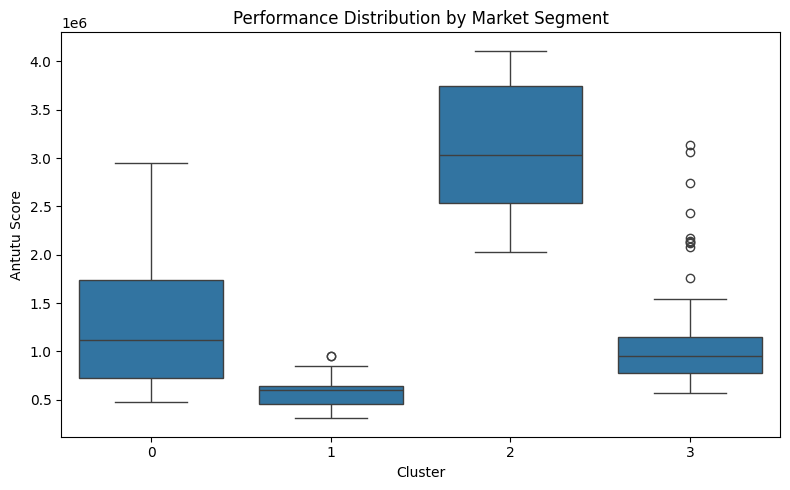

In [215]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=segmented_phones,
    x="cluster",
    y="antutu"
)

plt.title("Performance Distribution by Market Segment")
plt.xlabel("Cluster")
plt.ylabel("Antutu Score")

plt.tight_layout()
plt.show()

### 9. Processor Type by Cluster

In [216]:
processor_cluster = pd.crosstab(
    segmented_phones["processor_type"],
    segmented_phones["cluster"],
    normalize="index"
).round(2)

processor_cluster

cluster,0,1,2,3
processor_type,,,,
Apple Bionic,0.33,0.00,0.67,0.00
Exynos,0.69,0.00,0.31,0.00
Mediatek,0.06,0.43,0.05,0.46
Snapdragon,0.19,0.08,0.32,0.42
Tensor,1.00,0.00,0.00,0.00
Unisoc,0.00,1.00,0.00,0.00


### 10. Display Type by Cluster

In [217]:
display_cluster = pd.crosstab(
    segmented_phones["display_type"],
    segmented_phones["cluster"],
    normalize="index"
).round(2)

display_cluster

cluster,0,1,2,3
display_type,,,,
Amoled,0.29,0.0,0.25,0.46
IPS LCD,0.00,1.0,0.00,0.00


### 11. RAM and Storage Type by Cluster

In [218]:
pd.crosstab(
    segmented_phones["ram_type"],
    segmented_phones["cluster"],
    normalize="index"
).round(2)

cluster,0,1,2,3
ram_type,,,,
LPDDR4X,0.12,0.50,0.00,0.38
LPDDR5,0.57,0.00,0.00,0.43
LPDDR5X,0.28,0.04,0.41,0.28


In [219]:
pd.crosstab(
    segmented_phones["rom_type"],
    segmented_phones["cluster"],
    normalize="index"
).round(2)

cluster,0,1,2,3
rom_type,,,,
NVMe,0.33,0.00,0.67,0.00
UFS 2.2,0.12,0.58,0.00,0.30
UFS 3.1,0.32,0.14,0.00,0.54
UFS 4.0,0.30,0.00,0.50,0.20
UFS 4.1,0.15,0.00,0.52,0.33


### 12. Sales by Cluster

In [220]:
pd.crosstab(
    segmented_phones["sale"],
    segmented_phones["cluster"],
    normalize="index"
).round(2)

cluster,0,1,2,3
sale,,,,
Both,0.19,0.44,0.07,0.30
Flagship,0.33,0.00,0.67,0.00
Offline,0.26,0.26,0.00,0.49
Online,0.12,0.34,0.10,0.43


### 13. Examples from Clusters

In [221]:
for cluster in sorted(segmented_phones["cluster"].unique()):
    print(f"\nCLUSTER {cluster}")
    
    display(
        segmented_phones[
            segmented_phones["cluster"] == cluster
        ][
            [
                "brand",
                "name",
                "price",
                "antutu",
                "refresh_rate",
                "battery",
                "charging_speed"
            ]
        ]
        .sort_values("price")
        .head(10)
    )


CLUSTER 0


,brand,name,price,antutu,refresh_rate,battery,charging_speed
12,Samsung,Galaxy M17,20000,473905,90,5000,25
8,Samsung,Galaxy F36,21000,595209,120,5000,25
14,Samsung,Galaxy M36,21000,595209,120,5000,25
7,Samsung,Galaxy F17,23500,473905,90,5000,25
55,Nothing,Nothing Phone 3a Lite,28000,675102,120,5000,33
9,Samsung,Galaxy F56,28000,734661,120,5000,45
1,Samsung,Galaxy A17,28000,473905,90,5000,25
58,Nothing,Nothing Phone 4b,32000,1025914,120,6000,33
2,Samsung,Galaxy A27,34000,892500,120,5000,25
10,Samsung,Galaxy F70 Pro,36000,892500,120,6000,45



CLUSTER 1


,brand,name,price,antutu,refresh_rate,battery,charging_speed
85,POCO,Poco C81x,11500,341105,120,5200,15
84,POCO,Poco C81,12500,646000,120,6300,15
117,Xiaomi,Redmi A7,12500,341105,120,5200,15
41,Lava,Lava Bold N2,13000,515768,120,6000,18
43,Lava,Lava Virat V1,13000,500000,120,6000,18
51,Motorola,Moto G37,14000,596993,120,5200,20
118,Xiaomi,Redmi A7 Pro,15000,646000,120,6300,15
74,Oppo,Oppo K14x,16000,415000,120,6500,45
52,Motorola,Moto G37 Power,16000,596993,120,7000,30
128,Tecno,Tecno Pop X,16000,521017,120,6500,45



CLUSTER 2


,brand,name,price,antutu,refresh_rate,battery,charging_speed
49,Motorola,Moto Edge 70 Pro+,48000,2173245,144,6500,90
47,Motorola,Moto Edge 70 Max,55000,3061888,144,7100,90
17,Samsung,Galaxy S25 FE,60000,2073050,120,4900,45
54,Motorola,Moto Signature,60000,2858670,165,5200,90
61,OnePlus,Oneplus 15R,60000,3043315,165,7400,80
141,Vivo,Vivo X200T,60000,2825042,120,6200,90
145,Xiaomi,Xiaomi 15,65000,2632963,120,5240,90
21,Samsung,Galaxy S26 FE,73000,2533050,120,4900,45
104,Realme,Realme GT 8 Pro,73000,3975938,144,7000,120
15,Samsung,Galaxy S25,75000,2342380,120,4000,25



CLUSTER 3


,brand,name,price,antutu,refresh_rate,battery,charging_speed
45,Motorola,Moto Edge 60 Fusion,23000,700000,120,5500,68
42,Lava,Lava Virat Curve,24000,780000,120,6000,33
87,Xiaomi,Poco M8 Power,25000,619773,120,8000,45
107,Realme,Realme P4,26000,777255,144,7000,80
122,Xiaomi,Redmi Note 15 SE,26000,597923,120,5800,45
36,IQOO,Iqoo Neo 10R,27000,1540721,144,6400,80
26,Infinix,Infinix Note Edge,27000,719969,120,6500,45
106,Realme,Realme Narzo Power,28000,780000,144,10001,80
123,Xiaomi,Redmi Note 17,28000,619773,120,8000,45
131,Tecno,Tecno Pova Curve 2,28000,768617,144,8000,45
